# Free Energy Methods
Equilibrium constants, binding affinities, solubilities, and conformational populations are all determined by free energy differences, $\Delta G^\circ = -RT \ln K$. At room temperature, a factor of 10 in $K$ corresponds to only 1.36 kcal/mol, so useful predictions require an accuracy of about 1 kcal/mol. In this lecture, we discuss how free energy differences are computed from molecular simulations:
- **Alchemical methods** compute the free energy difference between two states, for example a molecule in the gas phase and in water.
- **Potentials of mean force and enhanced sampling** compute the free energy as a function of a coordinate, for example a dihedral angle.

## Free Energy Differences
The Helmholtz free energy is related to the canonical partition function by $A = -kT \ln Q$. Computing $Q$ itself is practically impossible for a liquid or a biomolecule, because it depends on the total volume of phase space, including all the high-energy configurations that a simulation never visits. Fortunately, we usually need only free energy *differences*, which depend on the *ratio* of two partition functions:
\begin{align}
    \Delta A_{\rm AB} = A_{\rm B} - A_{\rm A} = -kT \ln \frac{Q_{\rm B}}{Q_{\rm A}}
\end{align}
Because the free energy is a state function, $\Delta A$ can be computed along any path, including unphysical *alchemical* paths in which atoms are gradually made to disappear or change their identity. (At constant pressure, the same expressions give the Gibbs free energy.)

## Free Energy Perturbation
If states A and B have the same atoms but different potential energies $E_{\rm A}$ and $E_{\rm B}$, the ratio $Q_{\rm B}/Q_{\rm A}$ can be written as an average over configurations sampled from A. This gives the *Zwanzig equation*, the basis of *free energy perturbation* (FEP):
\begin{align}
    \Delta A_{\rm AB} = -kT \ln \left\langle e^{-(E_{\rm B} - E_{\rm A})/kT} \right\rangle_{\rm A}
\end{align}
We sample configurations from A and evaluate their energy with the potential of B. The equation is exact, but the exponential average is dominated by rare configurations of A that look like typical configurations of B. It only converges if the important regions of the two states *overlap*.

### Example: Two Harmonic Wells
State A is a broad harmonic well at $x = 0$ and state B is a narrow well at $x = 3$, with $E_{\rm A} = \frac{1}{2} k_{\rm A} x^2$, $E_{\rm B} = \frac{1}{2} k_{\rm B} (x - 3)^2$, $k_{\rm A} = 1$, $k_{\rm B} = 16$, and $kT = 1$. The exact answer is $\Delta A = \frac{kT}{2} \ln (k_{\rm B}/k_{\rm A})$. Since the Boltzmann distributions are Gaussians, we can draw perfectly uncorrelated samples, so any error comes from the estimator itself. We compute FEP in both directions (from samples of A, and from samples of B) and repeat each calculation 20 times.

Exact: 1.386 kT

       N   forward (from A)   reverse (from B)
     100     3.141 +- 2.400    -2.720 +- 1.359
    1000     1.821 +- 0.677    -2.167 +- 1.249
   10000     1.334 +- 0.130    -1.959 +- 0.697
  100000     1.383 +- 0.050    -1.678 +- 0.774


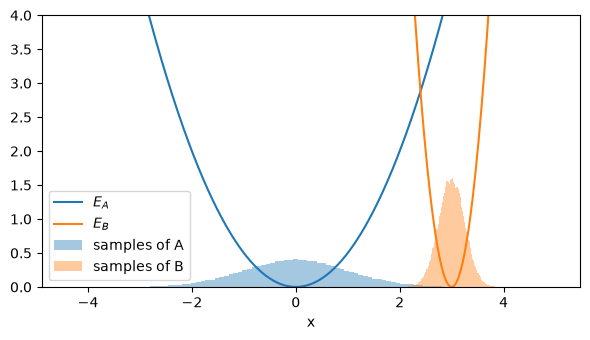

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

kT = 1.0
k_A, k_B, x_B = 1.0, 16.0, 3.0
exact = 0.5 * kT * np.log(k_B / k_A)

def E_A(x):
    return 0.5 * k_A * x**2

def E_B(x):
    return 0.5 * k_B * (x - x_B)**2

def E(lam, x):
    # Linear coupling between the two states: lambda = 0 is A and lambda = 1 is B
    return (1 - lam) * E_A(x) + lam * E_B(x)

def sample(lam, n, rng):
    # Boltzmann samples of E(lambda), which is also a harmonic well
    k = (1 - lam) * k_A + lam * k_B
    return rng.normal(lam * k_B * x_B / k, np.sqrt(kT / k), n)

rng = np.random.default_rng(2024)
print(f"Exact: {exact:.3f} kT\n\n{'N':>8s} {'forward (from A)':>18s} {'reverse (from B)':>18s}")
for n in [100, 1000, 10000, 100000]:
    forward = [-kT * np.log(np.mean(np.exp(-(E_B(x) - E_A(x)) / kT))) for x in (sample(0, n, rng) for _ in range(20))]
    reverse = [kT * np.log(np.mean(np.exp(-(E_A(x) - E_B(x)) / kT))) for x in (sample(1, n, rng) for _ in range(20))]
    print(f"{n:8d} {np.mean(forward):9.3f} +- {np.std(forward):5.3f} {np.mean(reverse):9.3f} +- {np.std(reverse):5.3f}")

x = np.linspace(-4, 5, 500)
plt.figure(figsize=(6, 3.5))
plt.plot(x, E_A(x), label="$E_A$")
plt.plot(x, E_B(x), label="$E_B$")
plt.hist(sample(0, 100000, rng), bins=100, density=True, alpha=0.4, color="C0", label="samples of A")
plt.hist(sample(1, 100000, rng), bins=100, density=True, alpha=0.4, color="C1", label="samples of B")
plt.ylim(0, 4)
plt.xlabel("x")
plt.legend()
plt.tight_layout()
plt.show()

The forward direction converges, but only with thousands of samples: the important configurations are the few samples of A that fall inside the narrow well of B. The reverse direction is badly *biased* and improves only very slowly, because the samples of B never visit most of the region that matters for A. A large difference between the forward and reverse estimates (*hysteresis*) is a sign of poor overlap.

## Intermediate States, Thermodynamic Integration, and MBAR
The overlap problem is solved by breaking the transformation into small steps. A coupling parameter $\lambda$ connects the two states, for example $E(\lambda) = (1 - \lambda) E_{\rm A} + \lambda E_{\rm B}$, and simulations are run at several intermediate $\lambda$ values ("windows"). The intermediate states have no physical meaning, but this does not matter because the free energy is a state function. The data from the windows can be combined in several ways:
- **Staged FEP:** sum the FEP free energies between neighboring windows.
- **Thermodynamic integration (TI):** integrate the derivative of the free energy,
\begin{align}
    \Delta A = \int_0^1 \left\langle \frac{\partial E(\lambda)}{\partial \lambda} \right\rangle_\lambda d\lambda
\end{align}
numerically over the windows. Only simple averages are needed, but the integrand must be smooth to avoid integration errors.
- **The Bennett acceptance ratio (BAR)** and its multistate generalization (**MBAR**) combine the samples from both sides of each window in a statistically optimal way. MBAR needs the reduced energy $E_k(\textbf{r}_n)/kT$ of every sample $n$ evaluated in every state $k$. It is the recommended estimator for most calculations and is implemented in the [pymbar](https://pymbar.readthedocs.io) package.

In [2]:
import logging
logging.getLogger("pymbar").setLevel(logging.ERROR)  # hide pymbar's notices about the optional JAX package
import pymbar

lambdas = np.linspace(0, 1, 11)
n = 1000  # samples per window
samples = [sample(lam, n, rng) for lam in lambdas]

staged = sum(-kT * np.log(np.mean(np.exp(-(E(lambdas[i + 1], x) - E(lambdas[i], x)) / kT)))
             for i, x in enumerate(samples[:-1]))
ti_11 = np.trapezoid([np.mean(E_B(x) - E_A(x)) for x in samples], lambdas)
lambdas_51 = np.linspace(0, 1, 51)
ti_51 = np.trapezoid([np.mean(E_B(x) - E_A(x)) for x in (sample(lam, n, rng) for lam in lambdas_51)], lambdas_51)

x_n = np.concatenate(samples)
u_kn = np.array([E(lam, x_n) / kT for lam in lambdas])  # reduced energy of every sample in every state
result = pymbar.MBAR(u_kn, np.full(len(lambdas), n)).compute_free_energy_differences()

print(f"Exact                       {exact:6.3f} kT")
print(f"Staged FEP (11 windows)     {staged:6.3f} kT")
print(f"TI (11 windows)             {ti_11:6.3f} kT")
print(f"TI (51 windows)             {ti_51:6.3f} kT")
print(f"MBAR (11 windows)           {result['Delta_f'][0, -1]:6.3f} +- {result['dDelta_f'][0, -1]:.3f} kT")

Exact                        1.386 kT
Staged FEP (11 windows)      1.438 kT
TI (11 windows)              3.074 kT
TI (51 windows)              1.427 kT
MBAR (11 windows)            1.445 +- 0.078 kT


With 11 windows, staged FEP and MBAR are close to the exact answer, and MBAR also provides an error bar. TI with 11 equally spaced windows overestimates the free energy because $\langle \partial E/\partial \lambda \rangle$ drops very steeply near $\lambda = 0$; more windows (or windows concentrated where the integrand changes quickly) are needed.

## Alchemical Free Energy Calculations
In alchemical calculations, $\lambda$ changes the chemical identity of the system, and these unphysical transformations are combined with physical processes in *thermodynamic cycles*. For example, the hydration free energy (the free energy of transferring a molecule from the gas phase into water) is computed with the cycle below. In each phase, the interactions between the solute and its environment are gradually turned off (*decoupled*). In the gas phase there is no environment, so $\Delta G_{\rm gas} = 0$, and $\Delta G_{\rm hyd} = -\Delta G_{\rm water}$.

<img src="hydration_cycle.png" alt="Thermodynamic cycle for the hydration free energy" width="550px"/>

The charges of the solute are usually turned off first, and then its Lennard-Jones interactions. Simply scaling the Lennard-Jones potential by $\lambda$ causes numerical problems near $\lambda = 0$: water molecules can overlap with the nearly transparent solute atoms, where the $r^{-12}$ term is enormous. This *end-point catastrophe* is avoided with a *soft-core* potential, which stays finite at $r = 0$ for $\lambda < 1$:
\begin{align}
    E_{\rm LJ}^{\rm sc}(r, \lambda) = 4 \epsilon \lambda \left[ \frac{1}{\left(\alpha(1 - \lambda) + (r/\sigma)^6\right)^2} - \frac{1}{\alpha(1 - \lambda) + (r/\sigma)^6} \right]
\end{align}

### Example: Hydration Free Energies of Small Molecules
We computed the hydration free energies of five molecules from the [FreeSolv database](https://github.com/MobleyLab/FreeSolv) with the OpenFF Sage 2.3 force field and TIP3P water, following the [alchemical free energy tutorial](https://openmm.github.io/openmm-cookbook/latest/notebooks/tutorials/Alchemical_free_energy_calculations.html) of the OpenMM cookbook. Each molecule is placed in a 2.4 nm box of water and decoupled through 15 states (5 to remove the charges and 11 to remove the soft-core Lennard-Jones interactions, sharing one state). Each state is sampled for 250 ps after 50 ps of equilibration, and every 1 ps the energy of the configuration is evaluated in all 15 states for MBAR. The functions that set up and run these simulations are in [simulations.py](simulations.py). The simulations take about 2.5 hours per molecule on a laptop CPU, so the results are provided in the `data` folder.

molecule       calculated  experiment  (kcal/mol)
methane       2.43 +- 0.08        2.00


ethanol      -4.12 +- 0.13       -5.00
benzene      -1.69 +- 0.14       -0.90
phenol       -6.85 +- 0.16       -6.60


acetamide    -8.18 +- 0.15       -9.71


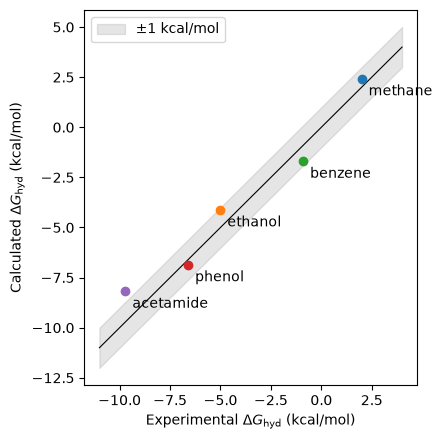

Root-mean-square error = 0.89 kcal/mol


In [3]:
import os
import simulations

molecules = {"methane": "C", "ethanol": "CCO", "benzene": "c1ccccc1", "phenol": "c1ccc(cc1)O", "acetamide": "CC(=O)N"}
experiment = {"methane": 2.00, "ethanol": -5.00, "benzene": -0.90, "phenol": -6.60, "acetamide": -9.71}  # FreeSolv
filename = "data/hydration_free_energies.npz"
if not os.path.exists(filename):
    simulations.compute_hydration_data(molecules, filename)
data = np.load(filename)

kT_kcal = 0.5925  # kcal/mol at 298.15 K
N_k = np.full(simulations.n_states, 250)
calculated = {}
print(f"{'molecule':10s} {'calculated':>14s} {'experiment':>11s}  (kcal/mol)")
for name in molecules:
    result = pymbar.MBAR(data[f"{name}_u_kn"], N_k).compute_free_energy_differences()
    # The decoupling free energy is f(decoupled) - f(coupled); the hydration free energy has the opposite sign
    calculated[name] = (-result["Delta_f"][0, -1] * kT_kcal, result["dDelta_f"][0, -1] * kT_kcal)
    print(f"{name:10s} {calculated[name][0]:7.2f} +- {calculated[name][1]:4.2f} {experiment[name]:11.2f}")

plt.figure(figsize=(4.5, 4.5))
for name, (dG, ddG) in calculated.items():
    plt.errorbar(experiment[name], dG, yerr=ddG, fmt="o")
    plt.annotate(name, (experiment[name], dG), textcoords="offset points", xytext=(5, -12))
line = np.array([-11, 4])
plt.plot(line, line, "k-", lw=0.8)
plt.fill_between(line, line - 1, line + 1, color="gray", alpha=0.2, label="$\\pm$1 kcal/mol")
plt.xlabel(r"Experimental $\Delta G_{\rm hyd}$ (kcal/mol)")
plt.ylabel(r"Calculated $\Delta G_{\rm hyd}$ (kcal/mol)")
plt.legend()
plt.tight_layout()
plt.show()
errors = np.array([calculated[name][0] - experiment[name] for name in molecules])
print(f"Root-mean-square error = {np.sqrt(np.mean(errors**2)):.2f} kcal/mol")

The calculations reproduce the experimental trend, from hydrophobic methane ($\Delta G_{\rm hyd} > 0$) to the strongly hydrophilic acetamide, with errors of about 1 kcal/mol that are typical of fixed-charge force fields. The small MBAR error bars only measure the statistical noise; the deviations from experiment come from the force field (the charges, the Lennard-Jones parameters, the water model, and the lack of polarization).

### Binding Free Energies
The most important application of alchemical methods is predicting protein-ligand binding affinities in drug design. The *relative* binding free energy of two similar ligands is computed by alchemically transforming ligand A into ligand B both in water and in the binding site:

<img src="relative_binding_cycle.png" alt="Thermodynamic cycle for relative binding free energies" width="600px"/>

Because only the parts of the ligands that differ are transformed, these calculations converge much faster than the physical binding process. For example, the [AMBER tutorial](https://ambermd.org/tutorials/advanced/tutorial9/index.html) on the L99A mutant of T4 lysozyme transforms benzene into phenol with TI. The two legs are large ($\Delta G_{\rm solvent} = -39.0$ and $\Delta G_{\rm complex} = -36.8$ kcal/mol, dominated by turning on the charges of the hydroxyl group), but they nearly cancel, giving $\Delta\Delta G_{\rm bind} = +2.2$ kcal/mol. Phenol binds more weakly than benzene, as observed experimentally: its hydroxyl group loses its hydrogen bonds with water when it enters the apolar cavity.

*Absolute* binding free energies are computed by decoupling the ligand both in water and in the binding site (*double decoupling*). Restraints keep the decoupled ligand in the binding site, and their analytical free energy provides the correction to the 1 M standard state.

## Potentials of Mean Force and Umbrella Sampling
The free energy as a function of a coordinate $\xi$ (a dihedral angle, a distance, etc.) is called the *potential of mean force* (PMF). It is related to the probability distribution of $\xi$:
\begin{align}
    A(\xi) = -kT \ln P(\xi) + C
\end{align}
In principle, $P(\xi)$ can be obtained from a histogram of an ordinary simulation, but high free energy regions are rarely visited. In *umbrella sampling*, a series of simulations ("windows") is performed, each with a harmonic bias $w_i(\xi) = \frac{1}{2} k (\xi - \xi_i)^2$ that holds the system near a different value $\xi_i$. Because the bias is known, the unbiased distribution can be recovered from each window, and the windows are combined with the *weighted histogram analysis method* (WHAM) or with MBAR.

### Example: The $\phi$ Dihedral of Alanine Dipeptide
Following the [AMBER umbrella sampling tutorial](https://ambermd.org/tutorials/advanced/tutorial17/index.php), we compute the PMF of the $\phi$ dihedral of alanine dipeptide in GBn2 implicit solvent with 36 windows ($-180^\circ$ to $170^\circ$, every $10^\circ$, force constant 200 kJ/mol/rad$^2$, 1 ns each). We compare it with a histogram from a 20 ns unbiased simulation (the same trajectory used in the molecular dynamics notes). The umbrella simulations take about an hour on a laptop CPU, so the results are provided.

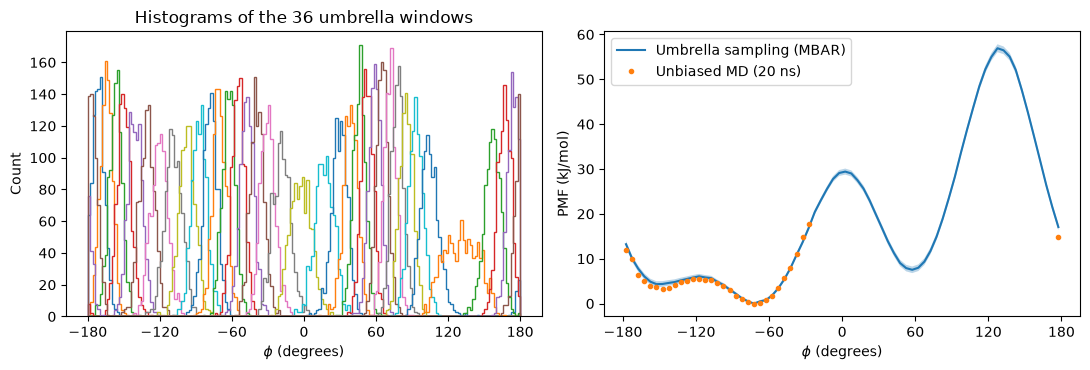

Population of phi > 0: 0.0275 from umbrella sampling, 0.0003 from unbiased MD


In [4]:
import mdtraj as md

kT = 2.494  # kJ/mol at 300 K
bins = np.linspace(-180, 180, 73)
centers = 0.5 * (bins[1:] + bins[:-1])

# PMF from the unbiased simulation
traj = md.load("data/alanine_dipeptide_gbn2.xtc", top="data/alanine_dipeptide.pdb")
phi_md = np.degrees(md.compute_phi(traj)[1][:, 0])
hist, _ = np.histogram(phi_md, bins=bins, density=True)
with np.errstate(divide="ignore"):
    pmf_md = -kT * np.log(hist)
pmf_md -= pmf_md[np.isfinite(pmf_md)].min()

# Umbrella sampling
window_centers = np.radians(np.arange(-180, 180, 10))
k_umbrella = 200.0  # kJ/mol/rad^2
filename = "data/umbrella_alanine_dipeptide.npz"
if not os.path.exists(filename):
    windows = np.array([simulations.run_umbrella_window(phi0, k_umbrella) for phi0 in window_centers])
    np.savez_compressed(filename, samples=windows, window_centers=window_centers, k=k_umbrella)
phi_windows = np.load(filename)["samples"][:, :, 0]  # (n_windows, n_samples), radians

# MBAR: reduced bias energy of every sample in every window (the unbiased energy cancels out)
def bias_energy(phi, phi0):
    dphi = np.abs(phi - phi0)
    dphi = np.minimum(dphi, 2 * np.pi - dphi)  # periodicity
    return 0.5 * k_umbrella * dphi**2

phi_n = phi_windows.flatten()
u_kn = np.array([bias_energy(phi_n, phi0) / kT for phi0 in window_centers])
fes = pymbar.FES(u_kn, np.full(len(window_centers), phi_windows.shape[1]))
fes.generate_fes(np.zeros(len(phi_n)), phi_n, fes_type="histogram",
                 histogram_parameters={"bin_edges": np.radians(bins)})
result = fes.get_fes(np.radians(centers), reference_point="from-lowest", uncertainty_method="analytical")
pmf_us, dpmf_us = result["f_i"] * kT, result["df_i"] * kT

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for window in phi_windows:
    axs[0].hist(np.degrees(window), bins=np.linspace(-180, 180, 181), histtype="step")
axs[0].set_xlabel(r"$\phi$ (degrees)")
axs[0].set_ylabel("Count")
axs[0].set_title("Histograms of the 36 umbrella windows")
axs[1].fill_between(centers, pmf_us - 2 * dpmf_us, pmf_us + 2 * dpmf_us, alpha=0.3)
axs[1].plot(centers, pmf_us, label="Umbrella sampling (MBAR)")
axs[1].plot(centers, pmf_md, "o", ms=3, label="Unbiased MD (20 ns)")
axs[1].set_xlabel(r"$\phi$ (degrees)")
axs[1].set_ylabel("PMF (kJ/mol)")
axs[1].legend()
for ax in axs:
    ax.set_xticks(range(-180, 181, 60))
fig.tight_layout()
plt.show()

positive = centers > 0
p_positive = np.sum(np.exp(-pmf_us[positive] / kT)) / np.sum(np.exp(-pmf_us / kT))
print(f"Population of phi > 0: {p_positive:.4f} from umbrella sampling, {np.mean(phi_md > 0):.4f} from unbiased MD")

The windows overlap along the whole range of $\phi$, including the barriers that the unbiased simulation never crossed. The two PMFs agree where the unbiased simulation sampled well, but the barriers near $\phi = 0^\circ$ and $120^\circ$ (about 30 and 55 kJ/mol) make transitions to positive $\phi$ so rare that the unbiased simulation underestimates the population of this region by about two orders of magnitude. The force constant must be large enough to hold each window in high free energy regions but small enough for neighboring windows to overlap, and all other slow motions must be sampled within each window.

## Metadynamics
In *metadynamics*, a single simulation builds up a history-dependent bias along one or a few collective variables (CVs) by adding small Gaussian "hills" at the current position at regular intervals. The bias fills the free energy minima like sand filling valleys, until the system diffuses freely over all values of the CVs. In *well-tempered* metadynamics, the hills shrink as the bias grows, and the bias converges to $-(1 - 1/\gamma)$ times the free energy surface, where $\gamma$ is the *bias factor*. Metadynamics is particularly useful for two-dimensional free energy surfaces, which would require many umbrella windows.

We ran 50 ns of well-tempered metadynamics of alanine dipeptide (GBn2) with both $\phi$ and $\psi$ as CVs (hills of 1 kJ/mol and width 20$^\circ$ every 1 ps, bias factor 6), using the `Metadynamics` class of OpenMM. The results are provided because the simulation takes a few hours.

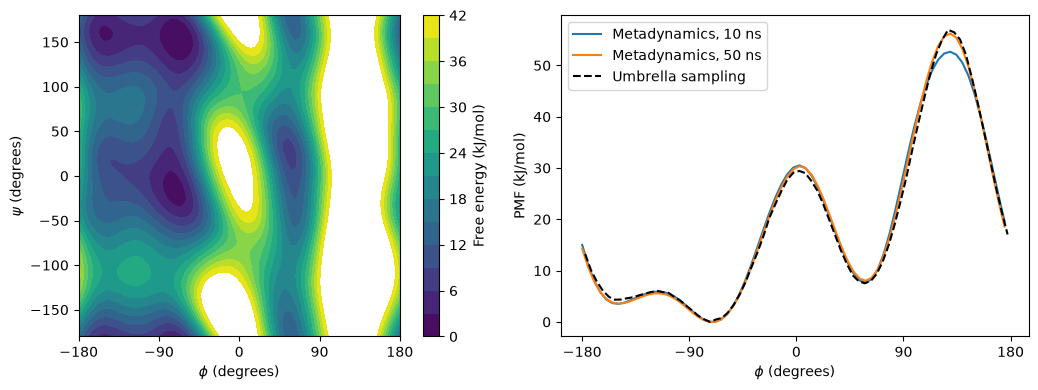

In [5]:
filename = "data/metadynamics_alanine_dipeptide.npz"
if not os.path.exists(filename):
    cv, free_energy = simulations.run_metadynamics()
    np.savez_compressed(filename, cv=cv, free_energy=free_energy)
free_energy = np.load(filename)["free_energy"]  # 50 snapshots of the surface, each indexed as [psi, phi]
grid = np.linspace(-180, 180, free_energy.shape[1])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
fes_2d = free_energy[-1] - free_energy[-1].min()
image = axs[0].contourf(grid, grid, fes_2d, levels=np.arange(0, 45, 3), cmap="viridis")
fig.colorbar(image, ax=axs[0], label="Free energy (kJ/mol)")
axs[0].set_xlabel(r"$\phi$ (degrees)")
axs[0].set_ylabel(r"$\psi$ (degrees)")
axs[0].set_aspect("equal")
# Project onto phi, A(phi) = -kT ln sum_psi exp(-A(phi, psi)/kT), after 10 ns and 50 ns
for index, label in [(9, "Metadynamics, 10 ns"), (-1, "Metadynamics, 50 ns")]:
    F = free_energy[index][:-1, :-1]  # the grid is periodic: the last point duplicates the first
    pmf_meta = -kT * np.log(np.sum(np.exp(-(F - F.min()) / kT), axis=0))
    axs[1].plot(grid[:-1], pmf_meta - pmf_meta.min(), label=label)
axs[1].plot(centers, pmf_us, "k--", label="Umbrella sampling")
axs[1].set_xlabel(r"$\phi$ (degrees)")
axs[1].set_ylabel("PMF (kJ/mol)")
axs[1].legend()
for ax in axs:
    ax.set_xticks(range(-180, 181, 90))
fig.tight_layout()
plt.show()

The free energy surface shows all the conformations of the Ramachandran plot, including the $\alpha_{\rm L}$ and C$_{7\rm ax}$ minima at positive $\phi$ that the unbiased simulation barely visited, and its projection onto $\phi$ converges to the umbrella sampling result.

## Other Methods
- **Replica exchange MD** (parallel tempering) runs copies of the system at different temperatures and swaps configurations between them, so that barriers crossed at high temperature are passed down to the temperature of interest. Replica exchange with solute tempering (REST) heats only the solute.
- **Steered MD and the Jarzynski equality** obtain free energies from the work $W$ of many nonequilibrium pulling simulations: $e^{-\Delta A/kT} = \langle e^{-W/kT} \rangle$.
- **MM/PBSA and MM/GBSA** estimate binding free energies from the force field energy and a continuum solvation model averaged over snapshots of the complex. They are cheap and useful for ranking compounds, but much less rigorous than alchemical methods.

## Best Practices
Free energy calculations can give precise-looking numbers that are wrong. Always check the overlap between neighboring states, compare different estimators (for example MBAR and TI), make sure that the result does not drift as more data are added, run independent replicas, and validate the protocol against experimental data for related systems.

## Useful Resources

- Chipot, C.; Pohorille, A., Eds. *Free Energy Calculations: Theory and Applications in Chemistry and Biology*; Springer: Berlin, 2007.
- Jensen, F. *Introduction to Computational Chemistry*, 3rd ed.; John Wiley & Sons: Nashville, TN, 2017. (Chapter 15)
- Mey, A. S. J. S. *et al.* Best Practices for Alchemical Free Energy Calculations. *Living J. Comput. Mol. Sci.* **2020**, *2*, 18378.
- Shirts, M. R.; Chodera, J. D. Statistically Optimal Analysis of Samples from Multiple Equilibrium States. *J. Chem. Phys.* **2008**, *129*, 124105.
- Zwanzig, R. W. High-Temperature Equation of State by a Perturbation Method. I. Nonpolar Gases. *J. Chem. Phys.* **1954**, *22*, 1420-1426.
- Beutler, T. C.; Mark, A. E.; van Schaik, R. C.; Gerber, P. R.; van Gunsteren, W. F. Avoiding Singularities and Numerical Instabilities in Free Energy Calculations Based on Molecular Simulations. *Chem. Phys. Lett.* **1994**, *222*, 529-539.
- Torrie, G. M.; Valleau, J. P. Nonphysical Sampling Distributions in Monte Carlo Free-Energy Estimation: Umbrella Sampling. *J. Comput. Phys.* **1977**, *23*, 187-199.
- Barducci, A.; Bussi, G.; Parrinello, M. Well-Tempered Metadynamics: A Smoothly Converging and Tunable Free-Energy Method. *Phys. Rev. Lett.* **2008**, *100*, 020603.
- Mobley, D. L.; Guthrie, J. P. FreeSolv: A Database of Experimental and Calculated Hydration Free Energies, with Input Files. *J. Comput.-Aided Mol. Des.* **2014**, *28*, 711-720.
- [The AMBER tutorials on free energy calculations](https://ambermd.org/tutorials/)
- [The OpenMM cookbook tutorials on alchemical free energies and umbrella sampling](https://openmm.github.io/openmm-cookbook/latest/tutorials)